In [1]:
from anemone.physics import *
from anemone import constants as c
from anemone.experiment import Receiver
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
sigma = 1/np.array([0.1, 10, 10])
sigma = torch.from_numpy(sigma).to(torch.float64)
thick = torch.tensor([40, 40])

omega = torch.tensor([2000], dtype=torch.float64)*2*c.pi

In [3]:
x,y,z = torch.linspace(-50, 50, 200), torch.linspace(-50, 50, 76), torch.linspace(0, 160, 301)

In [4]:
class Receiver:
    def __init__(self, x=0., y=0., z=0., grid=True) -> None:
        self.x = torch.tensor(x, dtype=torch.float64)
        self.y = torch.tensor(y, dtype=torch.float64)
        self.z = torch.tensor(z, dtype=torch.float64)
        
        if grid:
            self.grid()
        else:
            npoints = max(len(self.x), len(self.y),len(self.z))
            if len(self.x)==1: self.X = torch.ones(npoints)*self.x
            if len(self.y)==1: self.Y = torch.ones(npoints)*self.y
            if len(self.z)==1: self.Z = torch.ones(npoints)*self.z

    def grid(self):
        X,Y = torch.meshgrid(self.x, self.y, indexing='ij')
        self.shp = X.shape+(3,)
        self.X = X.squeeze()
        self.Y = Y.squeeze()
        self.Z = self.Y*0.
    
    @property
    def xyz(self):
        return torch.squeeze(torch.moveaxis(torch.stack((
                            self.X.flatten(), 
                            self.Y.flatten(), 
                            self.Z.flatten())), 0, -1))

    def __len__(self):
        return self.X.numel()

In [5]:
rx = Receiver(x, y, z)

C:\Users\au646858\AppData\Local\Temp\ipykernel_29376\805038302.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.x = torch.tensor(x, dtype=torch.float64)
C:\Users\au646858\AppData\Local\Temp\ipykernel_29376\805038302.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.y = torch.tensor(y, dtype=torch.float64)
C:\Users\au646858\AppData\Local\Temp\ipykernel_29376\805038302.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.z = torch.tensor(z, dtype=torch.float64)


In [934]:
import torch
from anemone.experiment import getRz
S1 = lambda x: 1 - (9/4)*x**2 * ( 1 - 2./9*x*(1 + 5/2*x*(1 - 2/5 * x)))
S2 = lambda x: -1/2*x*(1 - 11/6*x*(1 - 2/11*x*(1 + 5/2*x*(1-2/5*x))))

def lamontagne(x):
    phi   = x*0.
    xm2m1 = (-2 <= x)*(x < -1)
    xm1m0 = (-1 <= x)*(x < 0)
    x0p1  = (0 <= x)*(x <= 1)
    x1p2  = (1 < x)*(x <= 2)
    
    phi[xm2m1] = S2(-x[xm2m1]-1)
    phi[xm1m0] = S1(-x[xm1m0])
    phi[x0p1] = S1(x[x0p1])
    phi[x1p2] = S2(x[x1p2]-1)
    
    return phi


def s_of_rZ(self, rx, R):
    R = torch.tensor(R, dtype=torch.float64)
    logR = torch.log10(R)
    dR = R*torch.log(torch.tensor([10], dtype=torch.float64))*(logR.max()-logR.min())/R.numel()

    rx_xyz = rx.xyz
    n_rec  = len(rx)
    s      = torch.zeros((n_rec, )+R.shape, dtype=torch.complex128)
    R      = R [None, None, :]
    dR     = dR[None, None, :]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    for i in range(len(self)-1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        x1,y1 = p1[..., 0], p1[..., 1]
        x2,y2 = p2[..., 0], p2[..., 1]
        x_ = x1[:,None] + (x2-x1)[:,None]*torch.linspace(0, 1, 1001)[None, :]
        dx = (x_[..., 1] - x_[..., 0])[:,None]
        
        x1 = x1[:, None]
        x2 = x2[:, None]
        y1 = y1[:, None, None]
        x_ = x_[:, :, None]
        dx = dx[:, None]


        cr = torch.sqrt(y1**2 + x_**2)
        phi = lamontagne((cr-R)/dR)
        cs = y1 * phi * dx / cr
        s += cs.sum(axis=1, keepdims=False)

    return s


def s_of_rY(self, rx, R):
    R = torch.tensor(R, dtype=torch.float64)
    logR = torch.log10(R)
    dR = R*torch.log(torch.tensor([10], dtype=torch.float64))*(logR.max()-logR.min())/R.numel()

    rx_xyz = rx.xyz
    n_rec  = len(rx)
    sx      = torch.zeros((n_rec, )+R.shape, dtype=torch.complex128)
    sy      = torch.zeros((n_rec, )+R.shape, dtype=torch.complex128)
    R      = R [None, None, :]
    dR     = dR[None, None, :]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    for i in range(len(self)-1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        x1,y1 = p1[..., 0], p1[..., 1]
        x2,y2 = p2[..., 0], p2[..., 1]
        x_ = x1[:,None] + (x2-x1)[:,None]*torch.linspace(0, 1, 1001)[None, :]
        dx = (x_[..., 1] - x_[..., 0])[:,None]
        
        x1 = x1[:, None]
        x2 = x2[:, None]
        y1 = y1[:, None, None]
        x_ = x_[:, :, None]
        dx = dx[:, None]


        cr = torch.sqrt(y1**2 + x_**2)
        phi = lamontagne((cr-R)/dR)
        cs = (phi * dx).sum(axis=1, keepdims=False)
        
        sx += iRz[..., 0, 0, None]*cs
        sy += iRz[..., 0, 1, None]*cs
    return sx,sy


def s_of_r_ground(self, rx, R):
    R = torch.tensor(R, dtype=torch.float64)
    logR = torch.log10(R)
    dR = R*torch.log(torch.tensor([10], dtype=torch.float64))*(logR.max()-logR.min())/R.numel()

    rx_xyz = rx.xyz
    n_rec  = len(rx)
    sx      = torch.zeros((n_rec, )+R.shape, dtype=torch.complex128)
    sy      = torch.zeros((n_rec, )+R.shape, dtype=torch.complex128)
    R      = R [None, :]
    dR     = dR[None, :]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    for i in range(len(self)-1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        x1,y1 = p1[..., 0], torch.abs(p1[..., 1])
        x2,y2 = p2[..., 0], p2[..., 1]
        xm = (x1+x2)/2.

        cr1 = torch.sqrt(y1**2 + x1**2)[:, None]
        phi1 = lamontagne((cr1-R)/dR)
        cr2 = torch.sqrt(y1**2 + x2**2)[:, None]
        phi2 = lamontagne((cr2-R)/dR)
        y1 = y1[:, None]
        x1 = x1[:, None]
        x2 = x2[:, None]
        xm = xm[:, None]

        csx = torch.nan_to_num(phi2*y1/cr2-phi1*y1/cr1)
        csy = torch.nan_to_num(phi2*(x2-xm)/cr2-phi1*(x1-xm)/cr1)
        
        sx += iRz[..., 0, 0, None]*csx + iRz[..., 0, 1, None]*csy
        sy += iRz[..., 1, 0, None]*csx + iRz[..., 1, 1, None]*csy
    return sx,sy

In [948]:
from anemone.forwards import Forward
from anemone.physics import transverse_electric_field_coefficients as TEcoef, transverse_magnetic_field_coefficients as TMcoef
from anemone.transforms import Hankel

class BfieldFD(Forward):
    Fdn,Fup = None, None
    Adn,Aup = None, None
    un = None
    allr = None
    sz,sx,sy,dsy = None, None, None, None

    def __init__(self, source, receiver, freqs, waveform=None, filterfunc=None, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.freqs = freqs if isinstance(freqs, torch.Tensor) else torch.tensor(freqs)
        self.device = freqs.device

        self.rmin = self.source.min_horizontal_distance(self.receiver).to(self.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(self.device)
        self.filterfunc = filterfunc
        self.waveform = waveform
        self.tolerance=tolerance
        

        if self.device is not None:
            for attr_name in self.__dict__:
                attr_value = getattr(self, attr_name)
                if torch.is_tensor(attr_value):
                    setattr(self, attr_name, attr_value.to(self.device))      


    def forward(self):
        omega = c.twopi*self.freqs[:,None]

        def Hz_integrand(wave_length):
            """ Hz from horizontal electric dipole. """
            lmb = wave_length[None, :]

            if self.Fdn is None:
                self.Fdn,self.Fup, self.un = TEcoef(self.sigma, self.thick, omega, lmb, return_un=True)
                zbnd = torch.concatenate((torch.tensor([-torch.inf, 0.]), torch.cumsum(self.thick.squeeze().real, 0)))
                zsmp = self.receiver.z

                i_z = torch.searchsorted(zbnd, zsmp)-1
                zbnd[0] = 0.
                dz = zsmp-zbnd[i_z]

                Ftot = torch.zeros((zsmp.shape+self.Fdn[0].shape), dtype=torch.complex128)
                for i in range(len(zbnd)):
                    z_slice = i_z==i
                    if z_slice.any():
                        cz = dz[z_slice][:, None, None]
                        u = self.un[i][None, ...]
                        cA,cB = self.Fdn[i][None, ...], self.Fup[i][None, ...]
                        Ftot[z_slice] = cA * torch.exp(-u*cz) + cB * torch.exp(u*cz)                
                if self.filterfunc is not None:
                    Ftot *= self.filterfunc.omega_filter(omega)
                Ftot = torch.nan_to_num(Ftot)
            return torch.squeeze(Ftot/c.fourpi * lmb**2 / self.un[0])
        
        def Hxy_integrand(wave_length):
            lmb = wave_length[None, :]

            if self.Adn is None:
                self.Adn,self.Aup,un = TMcoef(self.sigma, self.thick, omega, lmb, return_un=True)
            zbnd = torch.concatenate((torch.tensor([-torch.inf, 0.]), torch.cumsum(self.thick.squeeze().real, 0)))
            zsmp = self.receiver.z

            i_z = torch.searchsorted(zbnd, zsmp)-1
            zbnd[0] = 0.
            dz = zsmp-zbnd[i_z]

            Atot = torch.zeros((zsmp.shape+self.Adn[0].shape), dtype=torch.complex128)
            for i in range(len(zbnd)):
                z_slice = i_z==i
                if z_slice.any():
                    cz = dz[z_slice][:, None, None]
                    u = self.un[i][None, ...]
                    cA,cB = self.Adn[i][None, ...], self.Aup[i][None, ...]
                    Atot[z_slice] = cA * torch.exp(-u*cz) + cB * torch.exp(u*cz)                
            if self.filterfunc is not None:
                Atot *= self.filterfunc.omega_filter(omega)
            Atot = torch.nan_to_num(Atot)
            
            Ftot = torch.zeros((zsmp.shape+self.Adn[0].shape), dtype=torch.complex128)
            for i in range(len(zbnd)):
                z_slice = i_z==i
                if z_slice.any():
                    cz = dz[z_slice][:, None, None]
                    u = self.un[i][None, ...]
                    cA,cB = self.Fdn[i][None, ...], self.Fup[i][None, ...]
                    Ftot[z_slice] = cA * torch.exp(-u*cz) - cB * torch.exp(u*cz)                
            if self.filterfunc is not None:
                Ftot *= self.filterfunc.omega_filter(omega)
            Ftot = torch.nan_to_num(Ftot)            

            return torch.squeeze((Atot-Ftot)/c.fourpi)

        def Hy_integrand(wave_length):
            lmb = wave_length[None, :]

            zbnd = torch.concatenate((torch.tensor([-torch.inf, 0.]), torch.cumsum(self.thick.squeeze().real, 0)))
            zsmp = self.receiver.z

            i_z = torch.searchsorted(zbnd, zsmp)-1
            zbnd[0] = 0.
            dz = zsmp-zbnd[i_z]
            
            Ftot = torch.zeros((zsmp.shape+self.Fdn[0].shape), dtype=torch.complex128)
            for i in range(len(zbnd)):
                z_slice = i_z==i
                if z_slice.any():
                    cz = dz[z_slice][:, None, None]
                    u = self.un[i][None, ...]
                    cA,cB = self.Fdn[i][None, ...], self.Fup[i][None, ...]
                    Ftot[z_slice] = cA * torch.exp(-u*cz) - cB * torch.exp(u*cz)                
            if self.filterfunc is not None:
                Ftot *= self.filterfunc.omega_filter(omega)
            Ftot = torch.nan_to_num(Ftot)            

            return torch.squeeze(Ftot/c.fourpi*lmb)
        

        hklz  = Hankel(Hz_integrand,  0, smp_per_decade=16, range=(self.rmin, self.rmax), device=self.device)
        hklxy = Hankel(Hxy_integrand, 1, smp_per_decade=16, range=(self.rmin, self.rmax), device=self.device)
        hkly  = Hankel(Hy_integrand,  0, smp_per_decade=16, range=(self.rmin, self.rmax), device=self.device)
        if self.sz is None:
            self.sz = s_of_rZ(self.source, self.receiver, hklz.r)
            self.sx,   self.sy = s_of_r_ground(self.source, self.receiver, hklxy.r)
            self.dsx, self.dsy = s_of_rY(self.source, self.receiver, hkly.r)


        HzR  = hklz(hklz.r)
        HxyR = hklxy(hklxy.r)
        HyR  = hkly(hkly.r)

        Hx = torch.einsum('ij,kj->ik', self.sx, HxyR)
        H = torch.zeros(Hx.shape+(3,), dtype=HzR.dtype)
        H[..., 0] = Hx
        H[..., 0] = torch.einsum('ij,kj->ik', self.dsx, HyR)

        H[..., 1]  = torch.einsum('ij,kj->ik', self.sy, HxyR)
        H[..., 1]  = torch.einsum('ij,kj->ik', self.dsy, HyR)
        H[..., 2]  = torch.einsum('ij,kj->ik', self.sz,  HzR)

        H = H.reshape(self.receiver.X.shape+self.receiver.z.shape+(3,))
        return H

In [949]:
from anemone.experiment import Loop

In [975]:
x = torch.linspace(-50, 50, 200)
tx = Loop.square(25)
rx = Receiver(x, 0.0, torch.linspace(0, 60, 200))
# rx = Receiver(0.01, x, torch.linspace(0, 60, 200))
fwr = BfieldFD(tx, rx, torch.tensor([2e3], dtype=torch.float64)*2*c.pi)

sigma = 1/torch.tensor([100, 50, 50])
thick = torch.tensor([20, 40])

H = fwr(sigma, thick)

C:\Users\au646858\AppData\Local\Temp\ipykernel_29376\805038302.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.x = torch.tensor(x, dtype=torch.float64)
C:\Users\au646858\AppData\Local\Temp\ipykernel_29376\805038302.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.z = torch.tensor(z, dtype=torch.float64)
c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)
c:\users\au646858\one

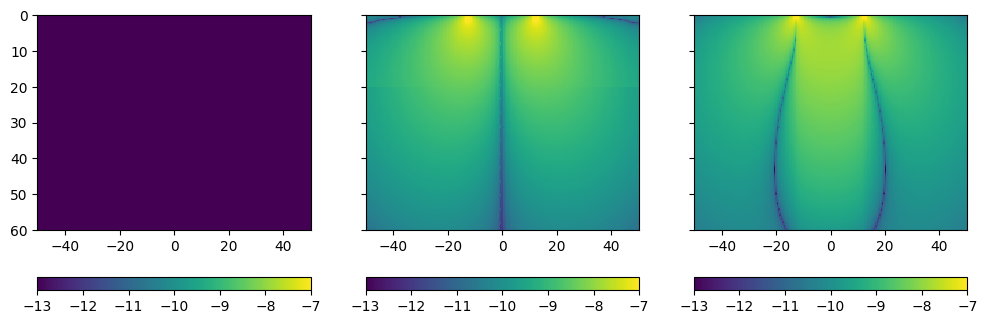

In [976]:
fig,axs = plt.subplots(1,3, sharex=True, sharey=True, figsize=(12, 4))
pcm=axs[0].pcolor(x, rx.z, np.log10(np.abs(H[:, :, 0].real.numpy().T)), vmin=-13, vmax=-7)
plt.colorbar(pcm, ax=axs[0], orientation='horizontal')
pcm=axs[1].pcolor(x, rx.z, np.log10(np.abs(H[:, :, 1].real.numpy().T)), vmin=-13, vmax=-7)
plt.colorbar(pcm, ax=axs[1], orientation='horizontal')
pcm=axs[2].pcolor(x, rx.z, np.log10(np.abs(H[:, :, 2].real.numpy().T)), vmin=-13, vmax=-7)
plt.colorbar(pcm, ax=axs[2], orientation='horizontal')
axs[0].invert_yaxis()

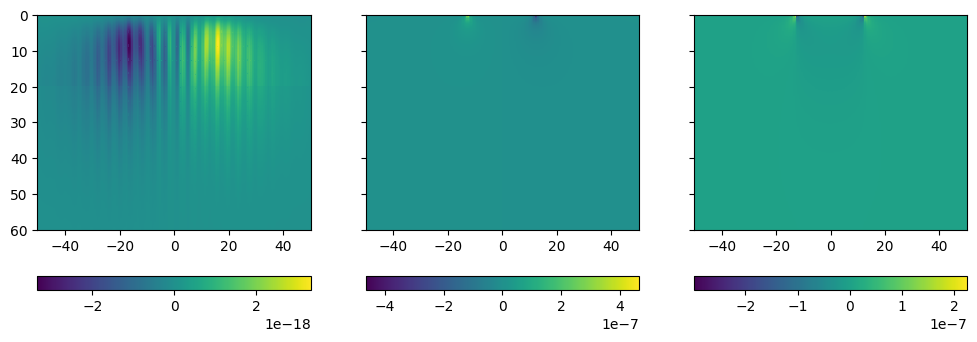

In [977]:
fig,axs = plt.subplots(1,3, sharex=True, sharey=True, figsize=(12, 4))
pcm=axs[0].pcolor(x, rx.z, H[:, :, 0].real.numpy().T)
plt.colorbar(pcm, ax=axs[0], orientation='horizontal')
pcm=axs[1].pcolor(x, rx.z, H[:, :, 1].real.numpy().T)
plt.colorbar(pcm, ax=axs[1], orientation='horizontal')
pcm=axs[2].pcolor(x, rx.z, H[:, :, 2].real.numpy().T)
plt.colorbar(pcm, ax=axs[2], orientation='horizontal')
axs[0].invert_yaxis()

In [978]:
decl = 0.
incl = 30.
def Bo_hat(incl, decl):
    inclrad =  incl*np.pi/180
    declrad = (decl-90)*np.pi/180
    return torch.tensor([np.cos(declrad)*np.cos(inclrad), np.sin(declrad)*np.cos(inclrad), np.sin(inclrad)])

Bo = Bo_hat(incl, decl).to(torch.complex128)

In [979]:
Bo

tensor([ 5.3029e-17+0.j, -8.6603e-01+0.j,  5.0000e-01+0.j],
       dtype=torch.complex128)

In [980]:
B_prll = torch.einsum('...i,...i->...', H, Bo)[..., None]*Bo
B_perp = H - B_prll

B_B_conj = torch.einsum('...i,...i->...', B_perp, B_perp.conj()).real
B_B_sqrd = torch.abs(torch.einsum('...i,...i->...', B_perp, B_perp))
BxB_conj = torch.cross(B_perp, B_perp.conj(), axis=-1)
sgn = torch.sgn(torch.einsum('...i,...i->...', BxB_conj, Bo)*1j)

alpha = torch.sqrt(0.5*(B_B_conj + B_B_sqrd)).real
beta  = (sgn*torch.sqrt(0.5*(B_B_conj - B_B_sqrd))).real

e_zeta = torch.sqrt(B_B_conj / B_B_sqrd).real

In [981]:
B1 = 0.5*(alpha-beta)

In [982]:
torch.abs(H).max()

tensor(4.6520e-07, dtype=torch.float64)

In [983]:
Htot = torch.einsum('...i,...i->...', H, H.conj()).real
print(Htot.max())

tensor(3.0559e-13, dtype=torch.float64)


C:\Users\au646858\AppData\Local\Temp\ipykernel_29376\902777703.py:3: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, ax=axs[0], orientation='horizontal')
C:\Users\au646858\AppData\Local\Temp\ipykernel_29376\902777703.py:5: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, ax=axs[1], orientation='horizontal')


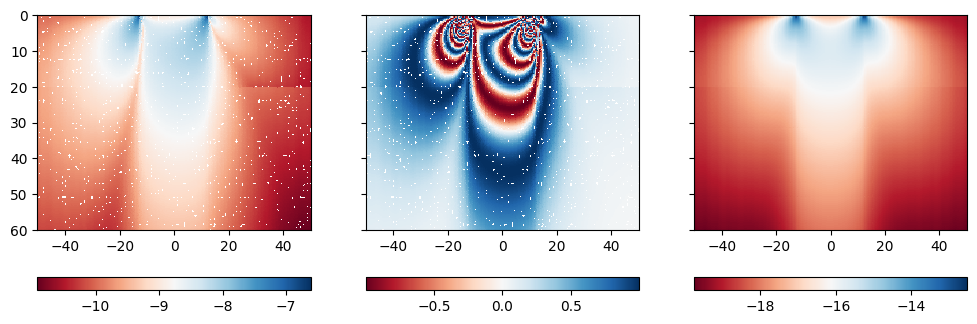

In [984]:
fig,axs = plt.subplots(1,3, sharex=True, sharey=True, figsize=(12, 4))
pcm=axs[0].pcolor(x, rx.z, np.log10(B1.T), cmap='RdBu')
plt.colorbar(pcm, ax=axs[0], orientation='horizontal')
pcm=axs[1].pcolor(x, rx.z, np.sin(2*np.pi*42577000.0*B1*0.04*150).numpy().T, cmap='RdBu')
plt.colorbar(pcm, ax=axs[1], orientation='horizontal')
pcm=axs[2].pcolor(x, rx.z, np.log10(Htot.T.numpy()), cmap='RdBu')
plt.colorbar(pcm, ax=axs[2], orientation='horizontal')
plt.gca().invert_yaxis()